# Verkeersveiligheid in België: analyse voor een presentatie
## tl;dr
Dit notebook vergelijkt de jaren 2017–2024 en onderzoekt in 2024 wanneer ongevallen gebeuren, wie de gewonde slachtoffers zijn en hoe de betrokken voertuigpopulatie is samengesteld. Alle conclusies worden uit de cellen hieronder berekend; losse figuren staan in `figures`.

## Samenvatting van de uitgevoerde run
**Uitgevoerde resultaten:** 35.932 letselongevallen en 469 doden binnen 30 dagen in 2024. Ten opzichte van 2017: respectievelijk -5.5% en -23.0%. De resultaten zijn beschrijvend; zonder verkeersblootstelling zijn verschillen geen risico per rit.

## Context & Methods
De vier gold-datasets hebben verschillende detailniveaus. We aggregeren elke bron zelfstandig; er is geen join op ongevalniveau.

### Key Assumptions
- Ongevallen: `SUM(MS_ACCT)`. Slachtoffers: aparte sommen van lichtgewonden, zwaargewonden en doden binnen 30 dagen. Ongedeerden zijn geen gewonden.
- Ernstpercentage: (zwaargewonden + doden binnen 30 dagen) / (lichtgewonden + zwaargewonden + doden binnen 30 dagen). Dit is een verdeling **onder geregistreerde gewonden/doden**, geen ongevalsrisico per rit of inwoner.
- Voertuigen: `SUM(FL_VEHICLE)` in de aangeleverde voertuigbron; een ongeval kan meerdere voertuigen hebben. De populatie van die bron is niet identiek aan alle weggebruikers.
- Geen verkeersintensiteiten, afgelegde kilometers of voertuigpark als noemer. Verschillen naar weggebruikers/voertuigen zijn beschrijvend, niet causaal.
- Tijdpatronen worden gecorrigeerd voor het aantal kalenderdagen per weekdag; ongeldige/ontbrekende uren worden expliciet buiten de uurfiguur gehouden.
- Categorieën hebben soms gewijzigde labels; de analyse naar weggebruiker gebruikt een expliciete, exporteerbare groepering van codes en focust op 2024.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

BASE = Path.cwd()
if not (BASE / 'reference_data').exists():
    BASE = BASE / 'analysis_notebooks'
assert (BASE / 'reference_data').exists(), 'Start Jupyter in group_assignment or analysis_notebooks.'
ROOT = BASE.parent
GOLD = ROOT / 'data' / 'gold'
FIG = BASE / 'figures'; FIG.mkdir(exist_ok=True)
TABLES = BASE / 'tables'; TABLES.mkdir(exist_ok=True)
YEAR = 2024
BLUE, ORANGE, GREY = '#175A78', '#D76B32', '#657581'
plt.rcParams.update({'figure.figsize':(12,7),'figure.dpi':110,'savefig.dpi':200,
 'font.family':'DejaVu Sans','font.size':11,'axes.titlesize':17,'axes.labelsize':11,
 'axes.spines.top':False,'axes.spines.right':False,'axes.edgecolor':'#BBC4CA',
 'axes.titleweight':'bold','axes.labelcolor':'#243440','text.color':'#243440',
 'xtick.color':'#465662','ytick.color':'#465662','figure.facecolor':'white'})
def number(v): return f'{v:,.0f}'.replace(',', '.')
def export(fig, name, source):
    fig.text(0.015, 0.015, source, fontsize=8, color=GREY)
    fig.savefig(FIG / f'{name}.png', bbox_inches='tight', facecolor='white')
    fig.savefig(FIG / f'{name}.svg', bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)
def load(name): return pd.read_parquet(GOLD/name/f'{name}.parquet')

## Data
### 1. Laden en tellingen vastleggen

In [2]:
a=load('road_accidents'); v=load('road_casualties'); vehicles=load('vehicle_collisions')
annual=a.groupby('analysis_year').MS_ACCT.sum().rename('ongevallen').to_frame()
victim_annual=v.groupby('analysis_year')[['MS_SLY_INJ','MS_SERLY_INJ','MS_DEAD_30_DAYS','MS_VIC_OK']].sum()
annual=annual.join(victim_annual,validate='one_to_one')
annual['gewonden_en_doden']=annual.MS_SLY_INJ+annual.MS_SERLY_INJ+annual.MS_DEAD_30_DAYS
annual['ernstig_of_dood']=annual.MS_SERLY_INJ+annual.MS_DEAD_30_DAYS
annual['ernstaandeel_pct']=100*annual.ernstig_of_dood/annual.gewonden_en_doden
assert annual.ongevallen.sum()==a.MS_ACCT.sum()
assert annual.gewonden_en_doden.sum()==v[['MS_SLY_INJ','MS_SERLY_INJ','MS_DEAD_30_DAYS']].sum().sum()
annual.to_csv(TABLES/'jaartotalen.csv')
display(annual.round(2))
a24=a[a.analysis_year==YEAR].copy(); v24=v[v.analysis_year==YEAR].copy()
veh24=vehicles[vehicles.analysis_year==YEAR].copy()
v24['gewonden_en_doden']=v24.MS_SLY_INJ+v24.MS_SERLY_INJ+v24.MS_DEAD_30_DAYS
v24['ernstig_of_dood']=v24.MS_SERLY_INJ+v24.MS_DEAD_30_DAYS

,ongevallen,MS_SLY_INJ,MS_SERLY_INJ,MS_DEAD_30_DAYS,MS_VIC_OK,gewonden_en_doden,ernstig_of_dood,ernstaandeel_pct
analysis_year,,,,,,,,
2017,38025,44710,3762,609,40842,49081,4371,8.91
2018,38453,45116,3637,604,41111,49357,4241,8.59
2019,37719,43583,3605,644,39915,47832,4249,8.88
2020,30251,33673,2978,499,30331,37150,3477,9.36
2021,34660,39005,3119,516,35817,42640,3635,8.52
2022,37650,42153,3413,540,38627,46106,3953,8.57
2023,36858,41489,3271,501,38357,45261,3772,8.33
2024,35932,40822,2999,469,37378,44290,3468,7.83


## Results
### 2. Nationale ontwikkeling
Drie afzonderlijke panelen houden de eenheden uit elkaar. De periode omvat 2020; de grafiek alleen identificeert geen oorzaak van de daling.

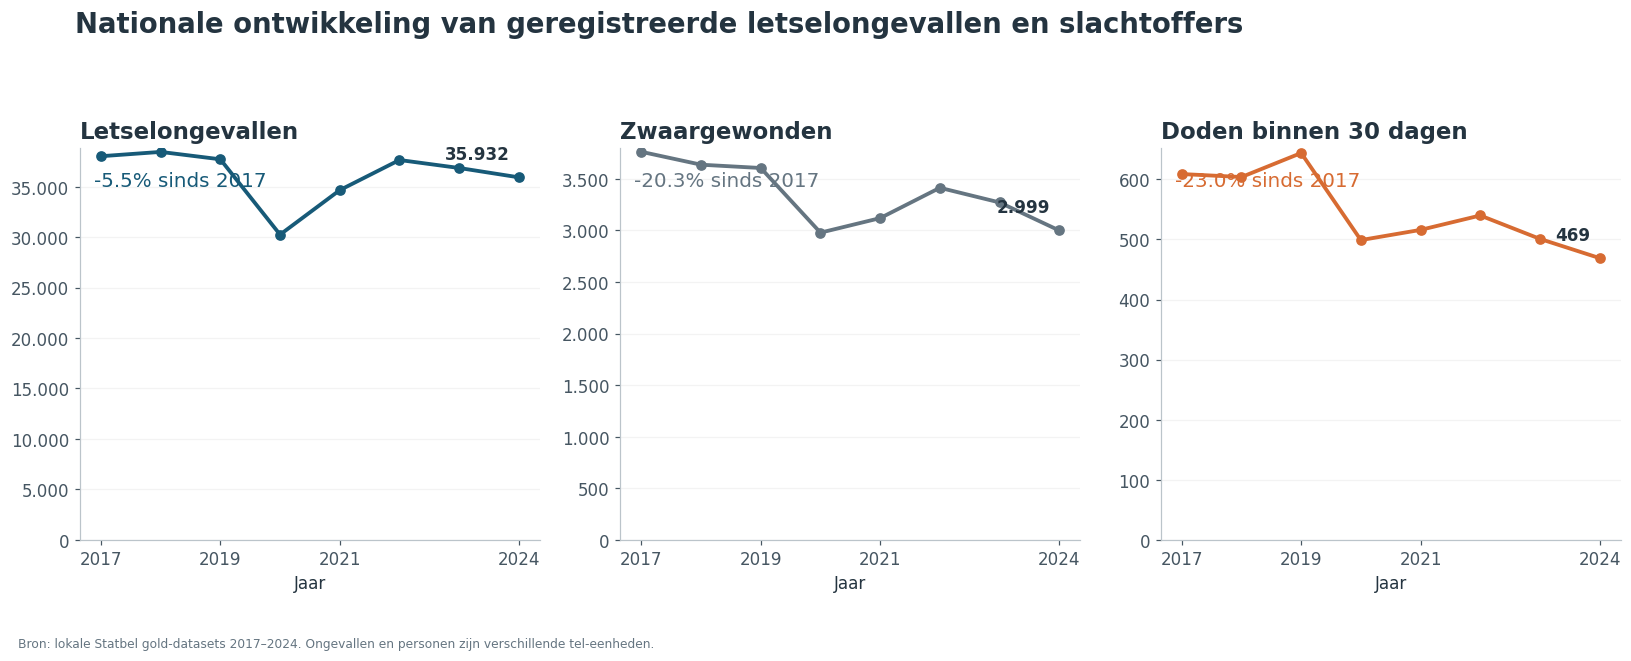

**Kernpunt:** 35.932 letselongevallen en 469 doden binnen 30 dagen in 2024. Verandering tegenover 2017: -5.5% en -23.0%.

In [3]:
fig,axes=plt.subplots(1,3,figsize=(15,6))
for ax,col,title,color in zip(axes,['ongevallen','MS_SERLY_INJ','MS_DEAD_30_DAYS'],
 ['Letselongevallen','Zwaargewonden','Doden binnen 30 dagen'],[BLUE,GREY,ORANGE]):
    ax.plot(annual.index,annual[col],marker='o',color=color,lw=2.5)
    ax.set_title(title,loc='left',fontsize=15); ax.set_ylim(bottom=0)
    ax.set_xticks([2017,2019,2021,2024]); ax.set_xlabel('Jaar'); ax.grid(axis='y',alpha=.15)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x,p:number(x)))
    change=100*(annual.loc[YEAR,col]/annual.loc[2017,col]-1)
    ax.text(.03,.94,f'{change:+.1f}% sinds 2017',transform=ax.transAxes,fontsize=13,color=color,va='top')
    ax.annotate(number(annual.loc[YEAR,col]),(YEAR,annual.loc[YEAR,col]),xytext=(-6,12),textcoords='offset points',ha='right',fontweight='bold')
fig.suptitle('Nationale ontwikkeling van geregistreerde letselongevallen en slachtoffers',x=.05,ha='left',fontweight='bold',fontsize=18)
fig.tight_layout(rect=(0,.07,1,.91))
export(fig,'05_nationale_trends','Bron: lokale Statbel gold-datasets 2017–2024. Ongevallen en personen zijn verschillende tel-eenheden.')
acc_change=float(100*(annual.loc[YEAR,'ongevallen']/annual.loc[2017,'ongevallen']-1))
death_change=float(100*(annual.loc[YEAR,'MS_DEAD_30_DAYS']/annual.loc[2017,'MS_DEAD_30_DAYS']-1))
display(Markdown(f"**Kernpunt:** {number(annual.loc[YEAR,'ongevallen'])} letselongevallen en {number(annual.loc[YEAR,'MS_DEAD_30_DAYS'])} doden binnen 30 dagen in {YEAR}. "
 f"Verandering tegenover 2017: {acc_change:+.1f}% en {death_change:+.1f}%."))

### 3. Gewesten: volume en ernst afzonderlijk
De aandelen worden berekend binnen hetzelfde slachtofferbestand. Niet delen door aantallen ongevallen uit een andere bron om een individueel risico te suggereren.

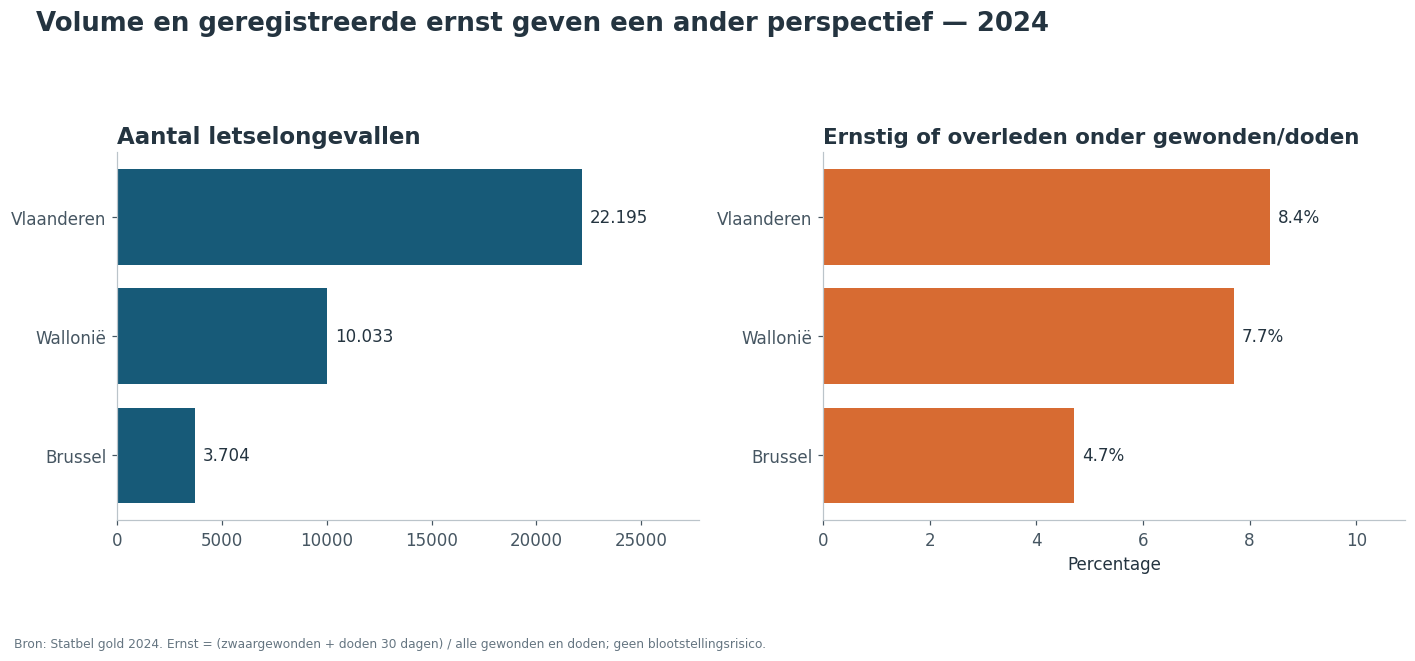

,ongevallen,gewonden_en_doden,ernstig_of_dood,ernstaandeel_pct
TX_RGN_DESCR_NL,,,,
Brussels Hoofdstedelijk Gewest,3704,4311,203,4.71
Waals Gewest,10033,12899,993,7.7
Vlaams Gewest,22195,27080,2272,8.39


In [4]:
regions=a24.groupby('TX_RGN_DESCR_NL').MS_ACCT.sum().rename('ongevallen').to_frame()
vr=v24.groupby('TX_RGN_DESCR_NL')[['gewonden_en_doden','ernstig_of_dood']].sum()
regions=regions.join(vr,validate='one_to_one').sort_values('ongevallen')
regions['ernstaandeel_pct']=100*regions.ernstig_of_dood/regions.gewonden_en_doden
assert regions.ongevallen.sum()==a24.MS_ACCT.sum()
regions.to_csv(TABLES/'gewesten_2024.csv')
names={'Vlaams Gewest':'Vlaanderen','Waals Gewest':'Wallonië','Brussels Hoofdstedelijk Gewest':'Brussel'}
labels=[names.get(x,x) for x in regions.index]
fig,axes=plt.subplots(1,2,figsize=(13,6))
axes[0].barh(labels,regions.ongevallen,color=BLUE)
axes[0].set_title('Aantal letselongevallen',loc='left',fontsize=15)
axes[0].bar_label(axes[0].containers[0],labels=[number(x) for x in regions.ongevallen],padding=5)
axes[0].set_xlim(0,regions.ongevallen.max()*1.25)
axes[1].barh(labels,regions.ernstaandeel_pct,color=ORANGE)
axes[1].set_title('Ernstig of overleden onder gewonden/doden',loc='left',fontsize=14)
axes[1].bar_label(axes[1].containers[0],labels=[f'{x:.1f}%' for x in regions.ernstaandeel_pct],padding=5)
axes[1].set_xlim(0,regions.ernstaandeel_pct.max()*1.3); axes[1].set_xlabel('Percentage')
fig.suptitle(f'Volume en geregistreerde ernst geven een ander perspectief — {YEAR}',x=.03,ha='left',fontsize=17,fontweight='bold')
fig.tight_layout(rect=(0,.1,1,.9))
export(fig,'06_gewesten_volume_ernst','Bron: Statbel gold 2024. Ernst = (zwaargewonden + doden 30 dagen) / alle gewonden en doden; geen blootstellingsrisico.')
display(regions.round(2))

### 4. Wanneer gebeuren ongevallen?
Gemiddeld aantal geregistreerde ongevallen per kalenderdag van de betreffende weekdag, per uur. Geen correctie voor verkeersdrukte; onbekende uren worden apart verantwoord.

C:\Users\arthu\Documents\Vlerick\1_Courses\MDP\group_assignment\analysis_notebooks\.runtime\ipykernel_72284\2821187423.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  time_data['weekday']=time_data.DT_DAY.dt.dayofweek
C:\Users\arthu\Documents\Vlerick\1_Courses\MDP\group_assignment\analysis_notebooks\.runtime\ipykernel_72284\2821187423.py:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  days=pd.Series(calendar.dayofweek).value_counts().sort_index()


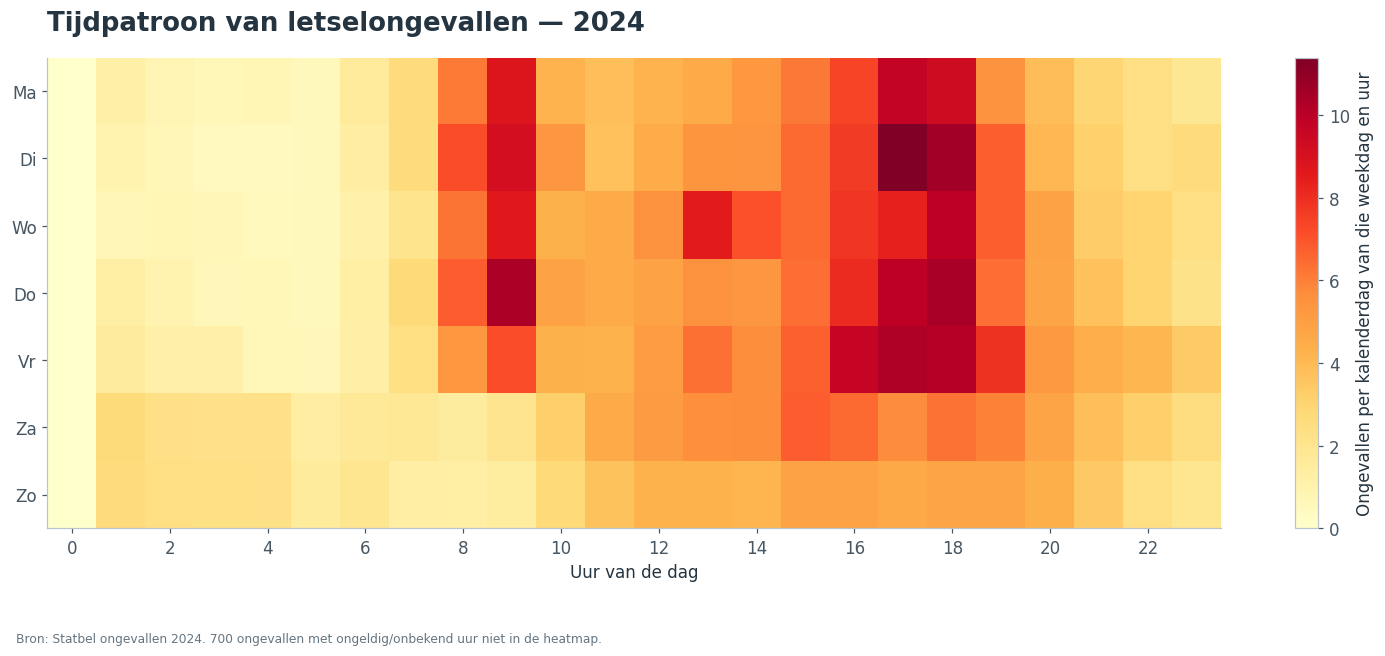

**Piek in deze registratie:** dinsdag om 17 uur, gemiddeld 11.40 ongevallen per betreffende kalenderdag. 700 ongevallen hebben geen bruikbaar uur. Verkeersintensiteit is niet beschikbaar.

In [5]:
valid_hour=a24.DT_HOUR.between(0,23).fillna(False)
excluded_hour=int(a24.loc[~valid_hour,'MS_ACCT'].sum())
time_data=a24.loc[valid_hour].copy()
time_data['weekday']=time_data.DT_DAY.dt.dayofweek
counts=time_data.pivot_table(index='weekday',columns='DT_HOUR',values='MS_ACCT',aggfunc='sum',fill_value=0).reindex(index=range(7),columns=range(24),fill_value=0)
calendar=pd.date_range(f'{YEAR}-01-01',f'{YEAR}-12-31')
days=pd.Series(calendar.dayofweek).value_counts().sort_index()
heat=counts.div(days,axis=0)
heat.to_csv(TABLES/'weekdag_uur_gemiddeld_2024.csv')
assert int(counts.to_numpy().sum())+excluded_hour==int(a24.MS_ACCT.sum())
fig,ax=plt.subplots(figsize=(14,6))
im=ax.imshow(heat.to_numpy(dtype=float),cmap='YlOrRd',aspect='auto')
ax.set_yticks(range(7),['Ma','Di','Wo','Do','Vr','Za','Zo']); ax.set_xticks(range(0,24,2))
ax.set_xlabel('Uur van de dag'); ax.set_title(f'Tijdpatroon van letselongevallen — {YEAR}',loc='left',pad=18)
fig.colorbar(im,ax=ax,label='Ongevallen per kalenderdag van die weekdag en uur')
fig.tight_layout(rect=(0,.08,1,1))
export(fig,'07_weekdag_uur',f'Bron: Statbel ongevallen {YEAR}. {number(excluded_hour)} ongevallen met ongeldig/onbekend uur niet in de heatmap.')
peak=np.unravel_index(np.nanargmax(heat.to_numpy(dtype=float)),heat.shape)
weekday_names=['maandag','dinsdag','woensdag','donderdag','vrijdag','zaterdag','zondag']
display(Markdown(f"**Piek in deze registratie:** {weekday_names[peak[0]]} om {peak[1]} uur, gemiddeld {heat.iloc[peak]:.2f} ongevallen per betreffende kalenderdag. "
 f"{number(excluded_hour)} ongevallen hebben geen bruikbaar uur. Verkeersintensiteit is niet beschikbaar."))

### 5. Welke weggebruikers dragen de geregistreerde letsellast?
De codegroepen hieronder zijn expliciet. Negatieve broncodes zijn echte categorieën in deze levering en worden niet als ontbrekend behandeld. De groepering is analytisch, geen nieuwe officiële classificatie.

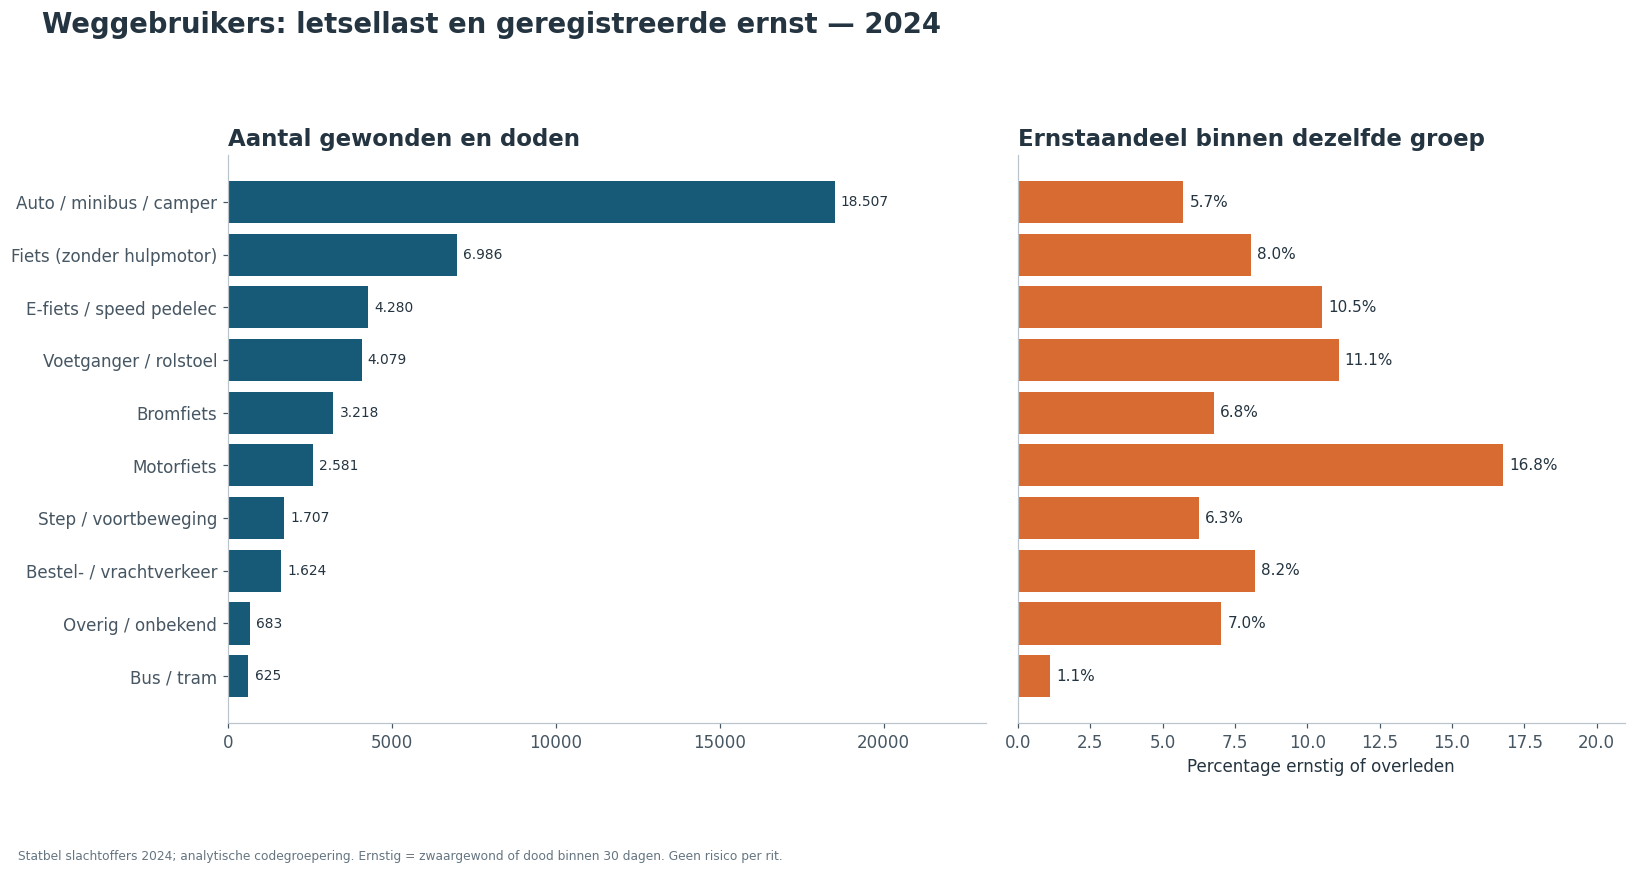

,gewonden_en_doden,ernstig_of_dood,MS_DEAD_30_DAYS,ernstaandeel_pct
weggebruiker,,,,
Bus / tram,625,7,0,1.12
Overig / onbekend,683,48,12,7.03
Bestel- / vrachtverkeer,1624,133,24,8.19
Step / voortbeweging,1707,107,4,6.27
Motorfiets,2581,433,57,16.78
Bromfiets,3218,218,10,6.77
Voetganger / rolstoel,4079,452,69,11.08
E-fiets / speed pedelec,4280,450,37,10.51
Fiets (zonder hulpmotor),6986,562,53,8.04


In [6]:
groups={
 'Auto / minibus / camper':['01','02','03','05'],
 'Fiets (zonder hulpmotor)':['18'],
 'E-fiets / speed pedelec':['25','26','27','-8'],
 'Motorfiets':['13','14','-5'],
 'Bromfiets':['15','16','17','-4'],
 'Voetganger / rolstoel':['20','21','22'],
 'Bestel- / vrachtverkeer':['04','06','07','08'],
 'Bus / tram':['10','11','12','-6'],
 'Step / voortbeweging':['28','95']}
lookup={c:name for name,codes in groups.items() for c in codes}
assert len(lookup)==sum(len(x) for x in groups.values())
v24['weggebruiker']=v24.CD_ROAD_USER_TYPE.map(lookup).fillna('Overig / onbekend')
mapping=v24[['CD_ROAD_USER_TYPE','TX_ROAD_USR_TYPE_DESCR_NL','weggebruiker']].drop_duplicates().sort_values('CD_ROAD_USER_TYPE')
mapping.to_csv(TABLES/'mapping_weggebruikers.csv',index=False)
mode=v24.groupby('weggebruiker')[['gewonden_en_doden','ernstig_of_dood','MS_DEAD_30_DAYS']].sum().sort_values('gewonden_en_doden')
mode['ernstaandeel_pct']=100*mode.ernstig_of_dood/mode.gewonden_en_doden.replace(0,np.nan)
assert mode.gewonden_en_doden.sum()==v24.gewonden_en_doden.sum()
mode.to_csv(TABLES/'weggebruikers_2024.csv')
fig,axes=plt.subplots(1,2,figsize=(15,8),gridspec_kw={'width_ratios':[1.25,1]})
axes[0].barh(mode.index,mode.gewonden_en_doden,color=BLUE)
axes[0].set_title('Aantal gewonden en doden',loc='left',fontsize=15)
axes[0].bar_label(axes[0].containers[0],labels=[number(x) for x in mode.gewonden_en_doden],padding=4,fontsize=9)
axes[0].set_xlim(0,mode.gewonden_en_doden.max()*1.25)
axes[1].barh(mode.index,mode.ernstaandeel_pct,color=ORANGE)
axes[1].set_yticks([]); axes[1].set_xlabel('Percentage ernstig of overleden')
axes[1].set_title('Ernstaandeel binnen dezelfde groep',loc='left',fontsize=15)
axes[1].bar_label(axes[1].containers[0],labels=[f'{x:.1f}%' for x in mode.ernstaandeel_pct],padding=4,fontsize=10)
axes[1].set_xlim(0,mode.ernstaandeel_pct.max()*1.25)
fig.suptitle(f'Weggebruikers: letsellast en geregistreerde ernst — {YEAR}',x=.03,ha='left',fontsize=18,fontweight='bold')
fig.tight_layout(rect=(0,.09,1,.92))
export(fig,'08_weggebruikers',f'Statbel slachtoffers {YEAR}; analytische codegroepering. Ernstig = zwaargewond of dood binnen 30 dagen. Geen risico per rit.')
display(mode.round(2))

### 6. Voertuigpopulatie bij geregistreerde aanrijdingen
De grafiek toont samenstelling, niet welk voertuigtype intrinsiek gevaarlijker is. Een verandering van het aandeel kan samenhangen met het wagenpark, het gebruik, de registratie of de ongevalsbetrokkenheid.

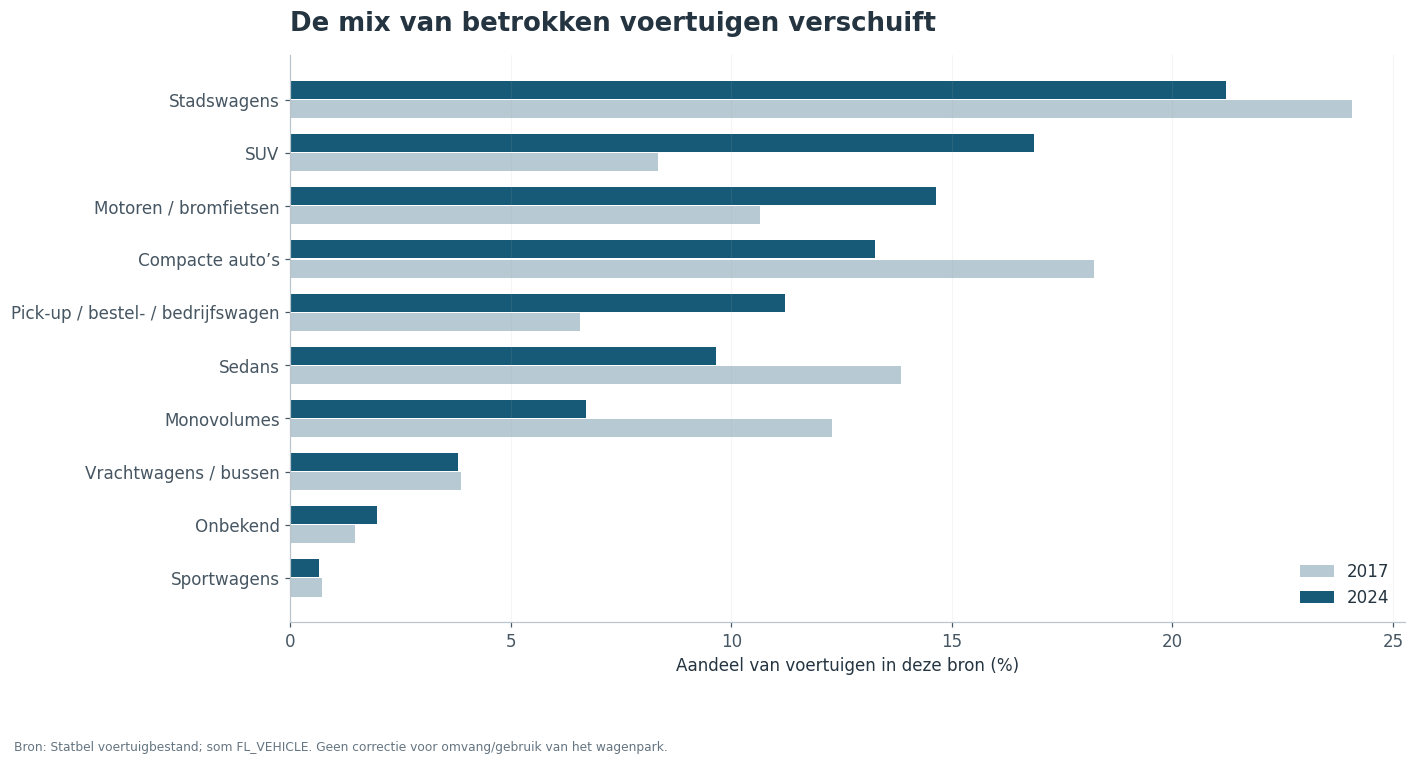

**Afbakening:** 85 voertuigen zonder bronjaar zijn buiten de jaarvergelijking gehouden. Het SUV-aandeel in deze bron gaat van 8.3% naar 16.9%. Dit bewijst geen groter individueel ongevalsrisico.

In [7]:
segment_names={'01':'Stadswagens','02':'Compacte auto’s','03':'Sedans','04':'SUV','05':'Monovolumes',
 '06':'Pick-up / bestel- / bedrijfswagen','07':'Vrachtwagens / bussen','08':'Motoren / bromfietsen',
 '09':'Sportwagens','99':'Onbekend'}
vehicles['segment']=vehicles.CD_VEHICLE_SEGMENT_B.map(segment_names).fillna('Onbekend')
mix=vehicles[vehicles.analysis_year.isin([2017,YEAR])].groupby(['analysis_year','segment']).FL_VEHICLE.sum().unstack(0,fill_value=0)
share=100*mix.div(mix.sum(axis=0),axis=1)
order=share[YEAR].sort_values().index; share=share.loc[order]
share.to_csv(TABLES/'voertuigmix_aandelen.csv'); mix.to_csv(TABLES/'voertuigmix_aantallen.csv')
fig,ax=plt.subplots(figsize=(13,7)); y=np.arange(len(share))
ax.barh(y-.18,share[2017],height=.34,color='#B7C9D2',label='2017')
ax.barh(y+.18,share[YEAR],height=.34,color=BLUE,label=str(YEAR))
ax.set_yticks(y,share.index); ax.set_xlabel('Aandeel van voertuigen in deze bron (%)')
ax.set_title('De mix van betrokken voertuigen verschuift',loc='left',pad=16); ax.legend(frameon=False)
ax.grid(axis='x',alpha=.12); fig.tight_layout(rect=(0,.09,1,1))
export(fig,'09_voertuigmix','Bron: Statbel voertuigbestand; som FL_VEHICLE. Geen correctie voor omvang/gebruik van het wagenpark.')
unknown_year_vehicles=int(vehicles.loc[vehicles.analysis_year.isna(),'FL_VEHICLE'].sum())
display(Markdown(f"**Afbakening:** {number(unknown_year_vehicles)} voertuigen zonder bronjaar zijn buiten de jaarvergelijking gehouden. "
 f"Het SUV-aandeel in deze bron gaat van {share.loc['SUV',2017]:.1f}% naar {share.loc['SUV',YEAR]:.1f}%. Dit bewijst geen groter individueel ongevalsrisico."))

### 7. Maandpatroon met kalendercorrectie
Aantal ongevallen gedeeld door het aantal dagen in de betreffende maand. Deze correctie maakt maanden vergelijkbaar qua lengte, maar corrigeert niet voor verkeer of weer.

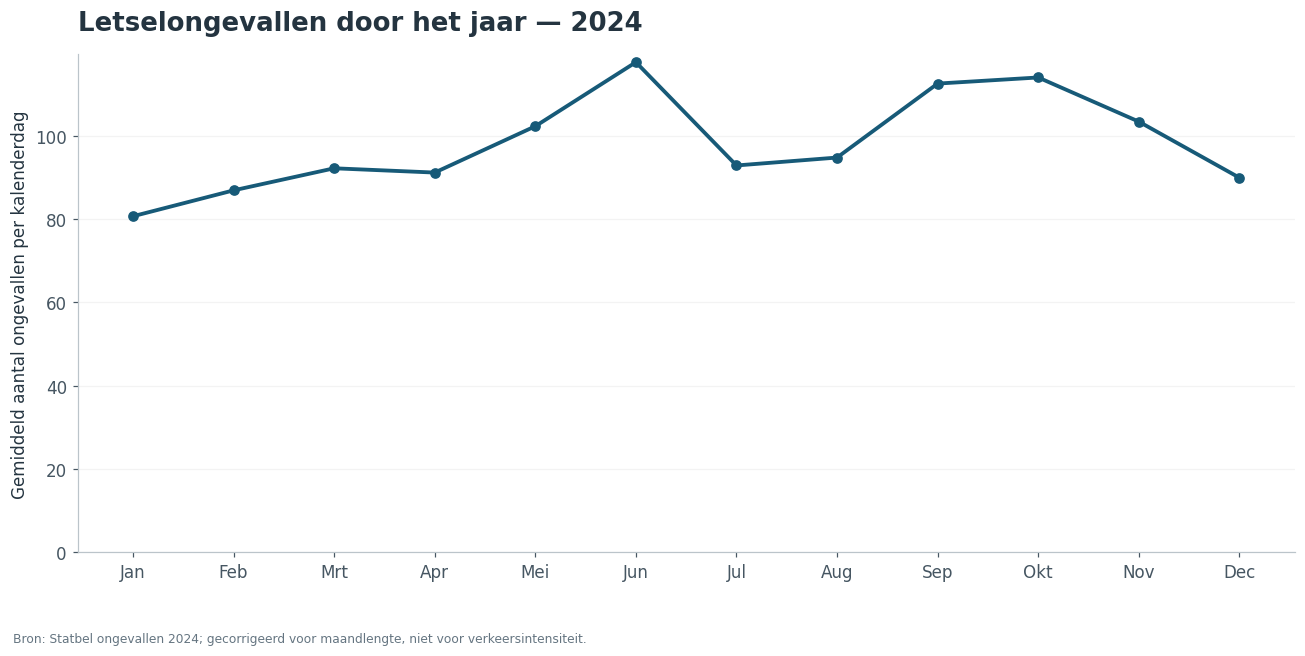

519

In [8]:
monthly=a24.groupby('analysis_month').MS_ACCT.sum().reindex(range(1,13))
month_days=pd.Series({m:pd.Period(f'{YEAR}-{m:02d}').days_in_month for m in range(1,13)})
monthly_daily=monthly/month_days
pd.DataFrame({'ongevallen':monthly,'kalenderdagen':month_days,'gemiddeld_per_dag':monthly_daily}).to_csv(TABLES/'maandpatroon_2024.csv')
fig,ax=plt.subplots(figsize=(12,6)); ax.plot(range(1,13),monthly_daily,color=BLUE,marker='o',lw=2.5)
ax.set_xticks(range(1,13),['Jan','Feb','Mrt','Apr','Mei','Jun','Jul','Aug','Sep','Okt','Nov','Dec'])
ax.set_ylim(bottom=0); ax.set_ylabel('Gemiddeld aantal ongevallen per kalenderdag')
ax.set_title(f'Letselongevallen door het jaar — {YEAR}',loc='left',pad=16); ax.grid(axis='y',alpha=.15)
fig.tight_layout(rect=(0,.08,1,1)); export(fig,'10_maandpatroon',f'Bron: Statbel ongevallen {YEAR}; gecorrigeerd voor maandlengte, niet voor verkeersintensiteit.')
summary={'year':YEAR,'accidents_2024':int(annual.loc[YEAR,'ongevallen']),'deaths_2024':int(annual.loc[YEAR,'MS_DEAD_30_DAYS']),
 'seriously_injured_2024':int(annual.loc[YEAR,'MS_SERLY_INJ']),'accident_change_pct':acc_change,'death_change_pct':death_change,
 'invalid_hour_accidents_2024':excluded_hour,'peak_weekday':weekday_names[peak[0]],'peak_hour':int(peak[1]),
 'peak_accidents_per_day':float(heat.iloc[peak]),'suv_share_2017':float(share.loc['SUV',2017]),'suv_share_2024':float(share.loc['SUV',YEAR]),
 'unknown_year_vehicles':unknown_year_vehicles,'highest_severity_group':str(mode.ernstaandeel_pct.idxmax()),
 'highest_severity_pct':float(mode.ernstaandeel_pct.max())}
(TABLES/'analysis_summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')

## Takeaways
- Gebruik de nationale trend als opening, gevolgd door het onderscheid tussen aantallen en geregistreerde ernst.
- De GeoPandas-kaarten geven ruimtelijke context. Vertel erbij hoeveel registraties geografisch bruikbaar zijn.
- De uur- en maandpatronen geven aanknopingspunten voor nader onderzoek. Zonder verkeersvolumes is er geen bewijs dat een tijdstip gevaarlijker is per rit.
- De letsellast per weggebruiker ondersteunt de keuze van vervolgvragen. De ernstpercentages zijn conditioneel op geregistreerde gewonden/doden en kunnen beïnvloed zijn door onderregistratie en samenstelling.
- De voertuigverdeling is een beschrijving van deze bron. Koppel een groeiend SUV-aandeel niet aan een causaal effect zonder wagenpark, gebruik en confounders te onderzoeken.

Alle exacte tabellen staan in `tables`. `PRESENTATIEVERHAAL.md` geeft een voorstel voor de volgorde en spreektekst. De eerdere datavoorbereiding staat in `../pipeline/HANDOVER.md`.

Brondefinities en beperkingen: [Statbel verkeersongevallen](https://statbel.fgov.be/nl/themas/mobiliteit/verkeer/verkeersongevallen), [methodologische nota voertuiggegevens](https://statbel.fgov.be/sites/default/files/files/opendata/Datalab-accidents/Accident_Method_en.pdf). De analyses gebruiken uitsluitend de aangeleverde periode 2017–2024, geen recentere tellingen van de website.